# F2 · Madde 3 — Her saldırı ailesi sırayla dışarıda (leave-one-family-out, LOFO)
**Profesörün notu:** *Her saldırı ailesini sırayla dışarıda bırakarak unseen-attack değerlendirmesini gerçekleştir.*

Bu protokol öneri v6 §7a.3'te (E7) **ilk doğrulayıcı çalıştırmadan önce** kaydedildi:
* 9 katman (fold): her saldırı ailesi bir kez görülmemiş; diğer 8 aile bilinen (geliştirme) aile;
* **yeni eğitim tohumları 10–19**; veri bölme tohumu değişmez; AE boyutu 32-16-8 sabit (katman başına seçim yok);
* karşılaştırma kümesi: AE (üç karar, akış düzeyi) · AE + Basamak 2 (host sayacı) · AE + Basamak 1 + Basamak 2 ·
  **yalnız RF** (8 bilinen aileyle eğitilir) eşleştirilmiş yanlış alarmda;
* W ∈ {20, 50, 100}, F ∈ {1.000, 5.000}, ρ ∈ {0,10; 0,25; 0,50; 1,00}. Sürüm B'de zaman damgası olmadığı için host
  pencereleri **simülasyondur**.

**Başarı ölçütü (§7a.3):** AE + Basamak 2, ρ = 1,0'da görülmemiş ailenin kaçan + ertelenen oranını **en az 30 puan**
azaltmalı ve en kötü hostun yanlış yükseltmesi bütçe içinde (haftada ≤ 1) kalmalı; bu **9 katmanın en az 6'sında** sağlanmalı.
**Başarısızlık ölçütü:** bilinenlere *benzemeyen* ailelerde (bu katmanda yalnız-RF recall < 0,50) yalnız RF, AE + Basamak 2'ye
yetişirse (≥ AE + Basamak 2 − 0,05), "yalnız normal veriyle" iddiası TON_IoT için geri çekilir ve veri kümesi bulgusu olarak raporlanır.
(< 0,50 ve 0,05 eşikleri öneride açık bırakılmıştı; bu defter çalıştırılmadan önce `configs/default.json`'da sabitlendi.)

**Neden AE her katmanda yeniden eğitilmiyor?** AE yalnız normal-eğitim verisini görür ve normal bölme saldırı aileleri
atanmadan önce çekilir; normal veri her katmanda aynıdır. Defter bunu varsaymaz, **assert** ile doğrular.
**Öneriden sapma (açıkça):** §7a.3 istemci başına (Mondrian) k\* kalibrasyonu yazar; bu merkezi LOFO'da istemci olmadığı için
k\* ara dönemdeki gibi normal-doğrulama pencerelerinden hesaplanır.

In [1]:
# ---- Kurulum (her defterde aynı): Drive'ı bağla, ortak kodu içe aktar ----
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
PROJECT_DIR = os.environ.get("TRUSTIDS_PROJECT", "/content/drive/MyDrive/TrustFed-TinyIDS-Final")
QUICK = os.environ.get("TRUSTIDS_QUICK", "0") == "1"   # hızlı mod YALNIZCA kodu test etmek içindir
# Devam modu: Colab oturumu kapanırsa, Drive'a kaydedilmiş tohumlar/adımlar atlanır ve kalan yerden devam edilir.
# Her şeyi baştan hesaplamak için: os.environ["TRUSTIDS_RESUME"] = "0"
RESUME = os.environ.get("TRUSTIDS_RESUME", "1") == "1"
sys.path.insert(0, PROJECT_DIR)

from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from trustids.config import Config
from trustids import utils

# Veri kümesi seçimi: varsayılan TON_IoT; ikinci veri kümesi için TRUSTIDS_CONFIG=edge_iiotset.json
CONFIG_NAME = os.environ.get("TRUSTIDS_CONFIG", "default.json")
CFG_PATH = Path(PROJECT_DIR) / "configs" / CONFIG_NAME
if CONFIG_NAME != "default.json" and not CFG_PATH.exists():
    raise FileNotFoundError(f"{CFG_PATH} bulunamadı: configs/ klasörünü de Drive'a yükleyin.")
cfg = Config.load(CFG_PATH) if CFG_PATH.exists() else Config(project_dir=PROJECT_DIR)
cfg.project_dir = PROJECT_DIR
if QUICK:
    cfg.train_seeds, cfg.validity_resplits, cfg.epochs = cfg.train_seeds[:2], 30, 15
    cfg.random_control_repeats, cfg.bootstrap_repeats = 10, 200
    cfg.lofo_seeds, cfg.fl_orig_rounds = cfg.lofo_seeds[:2], 3
    cfg.resolution_cal_windows, cfg.resolution_eval_windows = 600, 600
cfg.check()
ART = cfg.artifacts
FIG = Path(PROJECT_DIR) / cfg.figures_dir; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Proje klasörü:", PROJECT_DIR, "| hızlı mod:", QUICK, "| devam modu:", RESUME)
print("Drive'da kayıtlı ilerleme:", utils.progress(cfg))

Mounted at /content/drive
Proje klasörü: /content/drive/MyDrive/TrustFed-TinyIDS-Final | hızlı mod: False | devam modu: True
Drive'da kayıtlı ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '03_kararlar': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '04b_host_eslesmesi': True}


In [2]:
import tensorflow as tf
from trustids import data as D, models as M, conformal as C, resolution as R, lofo as L
raw = D.load_raw(cfg.data_path, cfg)
P0 = D.load_prepared(ART / "prepared")
spec = cfg.ae_variants[cfg.ae_default]            # önceden kaydedildiği gibi sabit: 32-16-8
LDIR = ART / "lofo"; (LDIR / "models").mkdir(parents=True, exist_ok=True)
FP = utils.fingerprint(cfg, ["lofo_seeds", "lofo_rf_trees", "resolution_windows", "resolution_flows_per_day",
                             "resolution_budget_per_week", "resolution_cal_windows", "resolution_eval_windows", "resolution_rho",
                             "alpha", "beta"])
FAMS = L.all_families(cfg)
RUN = utils.new_run_dir(Path(PROJECT_DIR) / cfg.runs_dir, "final_F2_lofo")
utils.save_json(utils.environment_info(), RUN / "environment.json"); cfg.save(RUN / "config_used.json")
print("katmanlar:", FAMS, "| tohumlar:", cfg.lofo_seeds, "| AE:", spec, "| parmak izi:", FP)

katmanlar: ['backdoor', 'ddos', 'dos', 'injection', 'password', 'scanning', 'ransomware', 'xss', 'mitm'] | tohumlar: [10, 11, 12, 13, 14, 15, 16, 17, 18, 19] | AE: {'hidden': [32, 16, 8], 'dropout': 0.0} | parmak izi: c874279878e7


## 1 · LOFO tohumları için AE eğitimi (yalnız normal veri; her tohum bir kez, Drive'a kaydedilir)

In [3]:
X0 = P0["X"]
for seed in cfg.lofo_seeds:
    mf, jf = LDIR / "models" / f"ae_seed{seed}.keras", LDIR / "models" / f"ae_seed{seed}.json"
    if RESUME and mf.exists() and jf.exists():
        print("tohum", seed, "Drive'da kayıtlı, atlanıyor (devam modu)"); continue
    utils.set_seed(seed)
    m = M.build_autoencoder(X0["benign_train"].shape[1], spec["hidden"], spec["dropout"], cfg.learning_rate)
    h = M.train_autoencoder(m, X0["benign_train"], X0["benign_val"], cfg.epochs, cfg.batch_size, cfg.patience,
                            conv_window=cfg.conv_window, conv_rel_tol=cfg.conv_rel_tol)
    m.save(mf)
    utils.save_json({"tohum": seed, "epoch": h["epochs_run"], "durma_nedeni": h["stopped_by"], "en_iyi_epoch": h["best_epoch"],
                     "en_iyi_dogrulama_kaybi": float(min(h["val_loss"]))}, jf)
    print("tohum", seed, "tamam:", h["epochs_run"], "epoch,", h["stopped_by"], flush=True)
TRS = pd.DataFrame([utils.load_json(LDIR / "models" / f"ae_seed{s}.json") for s in cfg.lofo_seeds])
TRS.to_csv(RUN / "F2_ae_egitim.csv", index=False); TRS

tohum 10 tamam: 810 epoch, relative_plateau
tohum 11 tamam: 1059 epoch, relative_plateau
tohum 12 tamam: 903 epoch, relative_plateau
tohum 13 tamam: 1056 epoch, relative_plateau
tohum 14 tamam: 1098 epoch, relative_plateau
tohum 15 tamam: 631 epoch, relative_plateau
tohum 16 tamam: 797 epoch, relative_plateau
tohum 17 tamam: 1179 epoch, relative_plateau
tohum 18 tamam: 1142 epoch, relative_plateau
tohum 19 tamam: 739 epoch, relative_plateau


,tohum,epoch,durma_nedeni,en_iyi_epoch,en_iyi_dogrulama_kaybi
0,10,810,relative_plateau,808,0.000734
1,11,1059,relative_plateau,1057,0.000799
2,12,903,relative_plateau,901,0.000726
3,13,1056,relative_plateau,1054,0.000804
4,14,1098,relative_plateau,1095,0.000828
5,15,631,relative_plateau,597,0.000868
6,16,797,relative_plateau,781,0.000752
7,17,1179,relative_plateau,1158,0.000720
8,18,1142,relative_plateau,1120,0.000854
9,19,739,relative_plateau,736,0.000852


## 2 · Katmanlar: hazırlama, normal-veri kontrolü, host eşlemesi ve değerlendirme (her katman × tohum Drive'a kaydedilir)

In [4]:
import json
SPL = ["benign_train", "benign_val", "benign_cal", "benign_test", "dev_test", "heldout_test"]
for fi, fam in enumerate(FAMS):
    fdir = LDIR / f"katman_{fam}"; fdir.mkdir(exist_ok=True)
    cfg_f = L.fold_config(cfg, fam)
    todo = [s for s in cfg.lofo_seeds if not (RESUME and (fdir / f"seed{s}_{FP}.json").exists())]
    if not todo:
        print(f"[{fam}] tüm tohumlar kayıtlı, atlanıyor"); continue
    if (fdir / "prepared" / "prepared.npz").exists():
        Pf = D.load_prepared(fdir / "prepared")
    else:
        print(f"[{fam}] hazırlanıyor...", flush=True)
        Pf = D.prepare(raw, cfg_f); D.save_prepared(Pf, fdir / "prepared")
        utils.save_json(Pf["report"], fdir / "prepare_report.json")
    assert L.same_benign(Pf, P0), f"{fam}: normal veri ana bölmeden farklı; AE yeniden kullanılamaz"
    hm = fdir / "host_rows.csv.gz"
    if hm.exists():
        ROWS = pd.read_csv(hm, keep_default_na=False); ROWS["split"] = ROWS["split"].replace({"": None})
    else:
        ROWS = R.map_rows(raw, Pf, cfg_f); ROWS.to_csv(hm, index=False)
    ROWS = ROWS[ROWS["split"].isin(["benign_val", "benign_test", "dev_test", "heldout_test"])].reset_index(drop=True)
    for seed in todo:
        ae = tf.keras.models.load_model(LDIR / "models" / f"ae_seed{seed}.keras", compile=False)
        S = {sp: M.ae_score(ae, Pf["X"][sp]) for sp in SPL}
        rf, thr = L.fit_rf(Pf, cfg_f, seed)
        flow = L.flow_level(Pf, S, rf, thr, cfg_f, fam, seed)
        host = L.host_level(ROWS, Pf, S, rf, thr, cfg_f, fam, seed, np.random.default_rng(10_000 + 100 * fi + seed))
        utils.save_json({"flow": flow, "host": host}, fdir / f"seed{seed}_{FP}.json")
        print(f"[{fam}] tohum {seed} tamam: AE ANOMALY {flow['AE_ANOMALY']:.3f} | RF {flow['RF_tek_recall_α']:.3f}", flush=True)
print("tüm katmanlar tamam")

[backdoor] hazırlanıyor...


/content/drive/MyDrive/TrustFed-TinyIDS-Final/trustids/data.py:210: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = pd.DataFrame({c: pd.to_numeric(df[c].replace("-", np.nan), errors="coerce")


[backdoor] tohum 10 tamam: AE ANOMALY 0.136 | RF 0.981
[backdoor] tohum 11 tamam: AE ANOMALY 0.972 | RF 0.979
[backdoor] tohum 12 tamam: AE ANOMALY 0.131 | RF 0.982
[backdoor] tohum 13 tamam: AE ANOMALY 0.136 | RF 0.989
[backdoor] tohum 14 tamam: AE ANOMALY 0.134 | RF 0.975
[backdoor] tohum 15 tamam: AE ANOMALY 0.131 | RF 0.976
[backdoor] tohum 16 tamam: AE ANOMALY 0.131 | RF 0.987
[backdoor] tohum 17 tamam: AE ANOMALY 0.132 | RF 0.978
[backdoor] tohum 18 tamam: AE ANOMALY 0.136 | RF 0.977
[backdoor] tohum 19 tamam: AE ANOMALY 0.132 | RF 0.983
[ddos] hazırlanıyor...
[ddos] tohum 10 tamam: AE ANOMALY 0.865 | RF 0.742
[ddos] tohum 11 tamam: AE ANOMALY 0.865 | RF 0.752
[ddos] tohum 12 tamam: AE ANOMALY 0.865 | RF 0.772
[ddos] tohum 13 tamam: AE ANOMALY 0.632 | RF 0.763
[ddos] tohum 14 tamam: AE ANOMALY 0.628 | RF 0.756
[ddos] tohum 15 tamam: AE ANOMALY 0.866 | RF 0.745
[ddos] tohum 16 tamam: AE ANOMALY 0.865 | RF 0.736
[ddos] tohum 17 tamam: AE ANOMALY 0.858 | RF 0.761
[ddos] tohum 18 tam

/content/drive/MyDrive/TrustFed-TinyIDS-Final/trustids/data.py:210: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = pd.DataFrame({c: pd.to_numeric(df[c].replace("-", np.nan), errors="coerce")


[dos] tohum 10 tamam: AE ANOMALY 0.050 | RF 0.767
[dos] tohum 11 tamam: AE ANOMALY 0.564 | RF 0.764
[dos] tohum 12 tamam: AE ANOMALY 0.052 | RF 0.770
[dos] tohum 13 tamam: AE ANOMALY 0.028 | RF 0.772
[dos] tohum 14 tamam: AE ANOMALY 0.029 | RF 0.773
[dos] tohum 15 tamam: AE ANOMALY 0.051 | RF 0.767
[dos] tohum 16 tamam: AE ANOMALY 0.051 | RF 0.773
[dos] tohum 17 tamam: AE ANOMALY 0.068 | RF 0.752
[dos] tohum 18 tamam: AE ANOMALY 0.008 | RF 0.763
[dos] tohum 19 tamam: AE ANOMALY 0.033 | RF 0.760
[injection] hazırlanıyor...
[injection] tohum 10 tamam: AE ANOMALY 0.080 | RF 0.750
[injection] tohum 11 tamam: AE ANOMALY 0.080 | RF 0.751
[injection] tohum 12 tamam: AE ANOMALY 0.080 | RF 0.746
[injection] tohum 13 tamam: AE ANOMALY 0.079 | RF 0.747
[injection] tohum 14 tamam: AE ANOMALY 0.079 | RF 0.754
[injection] tohum 15 tamam: AE ANOMALY 0.082 | RF 0.752
[injection] tohum 16 tamam: AE ANOMALY 0.082 | RF 0.746
[injection] tohum 17 tamam: AE ANOMALY 0.083 | RF 0.752
[injection] tohum 18 tam

/content/drive/MyDrive/TrustFed-TinyIDS-Final/trustids/data.py:210: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = pd.DataFrame({c: pd.to_numeric(df[c].replace("-", np.nan), errors="coerce")


[scanning] tohum 10 tamam: AE ANOMALY 0.106 | RF 0.998
[scanning] tohum 11 tamam: AE ANOMALY 0.949 | RF 0.998
[scanning] tohum 12 tamam: AE ANOMALY 0.106 | RF 0.998
[scanning] tohum 13 tamam: AE ANOMALY 0.054 | RF 0.998
[scanning] tohum 14 tamam: AE ANOMALY 0.055 | RF 0.998
[scanning] tohum 15 tamam: AE ANOMALY 0.106 | RF 0.997
[scanning] tohum 16 tamam: AE ANOMALY 0.106 | RF 0.997
[scanning] tohum 17 tamam: AE ANOMALY 0.106 | RF 0.997
[scanning] tohum 18 tamam: AE ANOMALY 0.010 | RF 0.997
[scanning] tohum 19 tamam: AE ANOMALY 0.061 | RF 0.998
[ransomware] hazırlanıyor...


/content/drive/MyDrive/TrustFed-TinyIDS-Final/trustids/data.py:210: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = pd.DataFrame({c: pd.to_numeric(df[c].replace("-", np.nan), errors="coerce")


[ransomware] tohum 10 tamam: AE ANOMALY 0.012 | RF 0.968
[ransomware] tohum 11 tamam: AE ANOMALY 0.008 | RF 0.968
[ransomware] tohum 12 tamam: AE ANOMALY 0.008 | RF 0.968
[ransomware] tohum 13 tamam: AE ANOMALY 0.008 | RF 0.952
[ransomware] tohum 14 tamam: AE ANOMALY 0.016 | RF 0.968
[ransomware] tohum 15 tamam: AE ANOMALY 0.012 | RF 0.948
[ransomware] tohum 16 tamam: AE ANOMALY 0.016 | RF 0.968
[ransomware] tohum 17 tamam: AE ANOMALY 0.012 | RF 0.964
[ransomware] tohum 18 tamam: AE ANOMALY 0.012 | RF 0.968
[ransomware] tohum 19 tamam: AE ANOMALY 0.012 | RF 0.968
[xss] hazırlanıyor...
[xss] tohum 10 tamam: AE ANOMALY 0.551 | RF 0.712
[xss] tohum 11 tamam: AE ANOMALY 0.550 | RF 0.865
[xss] tohum 12 tamam: AE ANOMALY 0.550 | RF 0.660
[xss] tohum 13 tamam: AE ANOMALY 0.551 | RF 0.707
[xss] tohum 14 tamam: AE ANOMALY 0.549 | RF 0.742
[xss] tohum 15 tamam: AE ANOMALY 0.578 | RF 0.620
[xss] tohum 16 tamam: AE ANOMALY 0.562 | RF 0.783
[xss] tohum 17 tamam: AE ANOMALY 0.556 | RF 0.728
[xss] to

/content/drive/MyDrive/TrustFed-TinyIDS-Final/trustids/data.py:210: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = pd.DataFrame({c: pd.to_numeric(df[c].replace("-", np.nan), errors="coerce")


[mitm] tohum 10 tamam: AE ANOMALY 0.052 | RF 0.845
[mitm] tohum 11 tamam: AE ANOMALY 0.051 | RF 0.837
[mitm] tohum 12 tamam: AE ANOMALY 0.057 | RF 0.832
[mitm] tohum 13 tamam: AE ANOMALY 0.049 | RF 0.845
[mitm] tohum 14 tamam: AE ANOMALY 0.053 | RF 0.828
[mitm] tohum 15 tamam: AE ANOMALY 0.057 | RF 0.819
[mitm] tohum 16 tamam: AE ANOMALY 0.053 | RF 0.827
[mitm] tohum 17 tamam: AE ANOMALY 0.056 | RF 0.821
[mitm] tohum 18 tamam: AE ANOMALY 0.023 | RF 0.833
[mitm] tohum 19 tamam: AE ANOMALY 0.059 | RF 0.846
tüm katmanlar tamam


## 3 · Akış düzeyi: her katmanda görülmemiş aile (tohum ortalaması ± std)

In [5]:
FLOW, HOST = [], []
for fam in FAMS:
    for s in cfg.lofo_seeds:
        z = utils.load_json(LDIR / f"katman_{fam}" / f"seed{s}_{FP}.json")
        FLOW.append(z["flow"]); HOST += z["host"]
FLOW, HOST = pd.DataFrame(FLOW), pd.DataFrame(HOST)
FLOW.to_csv(RUN / "F2_akis_tum_tohumlar.csv", index=False); HOST.to_csv(RUN / "F2_host_tum_tohumlar.csv", index=False)
fcols = ["AE_ANOMALY", "AE_UNCERTAIN", "AE_kaçan", "AE_ANOMALY_çakışma_kaçmış", "RF_tek_recall_α", "RF_tek_recall_α+β",
         "AE+Basamak1_recall", "normal_AE_ANOMALY", "normal_RF_FPR_α", "normal_AE+Basamak1_FPR"]
FT = FLOW.groupby("aile", sort=False)[fcols].agg(["mean", "std"]).round(4)
FT.to_csv(RUN / "F2_akis_katman_ozet.csv"); FT

AE_ANOMALY         AE_UNCERTAIN         AE_kaçan         AE_ANOMALY_çakışma_kaçmış         RF_tek_recall_α         RF_tek_recall_α+β          \
                 mean     std         mean     std     mean     std                      mean     std            mean     std              mean     std   
aile                                                                                                                                                      
backdoor       0.2170  0.2652       0.7732  0.2652   0.0098  0.0000                    0.2170  0.2652          0.9807  0.0049            0.9922  0.0000   
ddos           0.7698  0.1217       0.1517  0.1219   0.0785  0.0007                    0.7697  0.1217          0.7545  0.0109            0.9977  0.0004   
dos            0.0933  0.1662       0.5500  0.1698   0.3567  0.0046                    0.0931  0.1662          0.7662  0.0066            0.8496  0.0259   
injection      0.0803  0.0016       0.0966  0.0013   0.8231  0.0004                    0.0803  0.0016          0.7494  0.0030            0.9994  0.0000   
password       0.0698  0.0380       0.0896  0.0385   0.8406  0.0010                    0.0698  0.0380          0.7148  0.0704            0.9993  0.0003   
scanning       0.1657  0.2772       0.8140  0.2799   0.0203  0.0034                    0.1653  0.2772          0.9974  0.0004            1.0000  0.0000   
ransomware     0.0117  0.0030       0.9847  0.0037   0.0036  0.0030                    0.0101  0.0021          0.9637  0.0076            0.9996  0.0013   
xss            0.5585  0.0107       0.3270  0.0116   0.1144  0.0046                    0.5585  0.0107          0.7254  0.0659            0.9999  0.0000   
mitm           0.0512  0.0105       0.3972  0.0408   0.5516  0.0415                    0.0502  0.0105          0.8334  0.0100            0.9785  0.0018   

           AE+Basamak1_recall         normal_AE_ANOMALY         normal_RF_FPR_α         normal_AE+Basamak1_FPR          
                         mean     std              mean     std            mean     std                   mean     std  
aile                                                                                                                    
backdoor               0.9859  0.0028            0.0078  0.0011          0.0090  0.0004                 0.0121  0.0011  
ddos                   0.8253  0.1167            0.0078  0.0011          0.0090  0.0005                 0.0120  0.0009  
dos                    0.6166  0.0066            0.0078  0.0011          0.0099  0.0003                 0.0122  0.0010  
injection              0.1759  0.0004            0.0078  0.0011          0.0101  0.0006                 0.0122  0.0011  
password               0.1584  0.0009            0.0078  0.0011          0.0099  0.0008                 0.0122  0.0011  
scanning               0.9782  0.0032            0.0078  0.0011          0.0103  0.0006                 0.0122  0.0010  
ransomware             0.9685  0.0082            0.0078  0.0011          0.0093  0.0006                 0.0123  0.0009  
xss                    0.8300  0.0116            0.0078  0.0011          0.0084  0.0007                 0.0111  0.0010  
mitm                   0.3529  0.0370            0.0078  0.0011          0.0096  0.0006                 0.0117  0.0010

## 4 · Host düzeyi (Basamak 2) ve önceden kaydedilmiş başarı / başarısızlık ölçütleri

In [6]:
rho1 = "karisik_ρ=1.00"
hcols = ["k_yildiz", "normal_haftalik_ort", "normal_haftalik_p95_host", "normal_haftalik_en_kotu_host", "saf_pencere_tespit"] + \
        [c for c in HOST.columns if c.startswith("karisik_")] + ["cikmaz_orani"]
HT = HOST.groupby(["sistem", "W", "F", "aile"], sort=False)[hcols].mean()
HT.to_csv(RUN / "F2_host_katman_ozet.csv")
fm = FLOW.groupby("aile")[["AE_ANOMALY", "RF_tek_recall_α"]].mean()
verdict = []
for (sysn, W, F), g in HOST[HOST["sistem"] == "AE + Basamak 2"].groupby(["sistem", "W", "F"]):
    gm = g.groupby("aile")[[rho1, "normal_haftalik_en_kotu_host"]].mean()
    gm = gm.join(fm)
    gm["azalma_puan"] = 100 * (gm[rho1] - gm["AE_ANOMALY"])          # kaçan+ertelenen akış − host düzeyi kaçan
    gm["bütçe_içinde"] = gm["normal_haftalik_en_kotu_host"] <= cfg.resolution_budget_per_week
    gm["katman_başarılı"] = (gm["azalma_puan"] >= 100 * cfg.lofo_success_points) & gm["bütçe_içinde"]
    gm["benzemeyen_aile"] = gm["RF_tek_recall_α"] < cfg.lofo_unlike_rf_recall
    gm["RF_yetişiyor"] = gm["RF_tek_recall_α"] >= gm[rho1] - cfg.lofo_match_margin
    n_ok = int(gm["katman_başarılı"].sum())
    fail = bool((gm["benzemeyen_aile"] & gm["RF_yetişiyor"]).any())
    verdict.append({"W": W, "F": F, "başarılı_katman": n_ok, "katman": len(gm),
                    "başarı_ölçütü_sağlandı": n_ok >= cfg.lofo_success_folds,
                    "benzemeyen_aileler": ", ".join(gm.index[gm["benzemeyen_aile"]]) or "yok",
                    "başarısızlık_ölçütü_tetiklendi": fail})
    gm.round(4).to_csv(RUN / f"F2_olcut_W{W}_F{F}.csv")
VER = pd.DataFrame(verdict); VER.to_csv(RUN / "F2_on_kayitli_olcutler.csv", index=False); VER

,W,F,başarılı_katman,katman,başarı_ölçütü_sağlandı,benzemeyen_aileler,başarısızlık_ölçütü_tetiklendi
0,20,1000,0,9,False,yok,False
1,20,5000,0,9,False,yok,False
2,50,1000,8,9,True,yok,False
3,50,5000,7,9,True,yok,False
4,100,1000,8,9,True,yok,False
5,100,5000,8,9,True,yok,False


Sonuçlar: /content/drive/MyDrive/TrustFed-TinyIDS-Final/runs/20261111-060847_final_F2_lofo


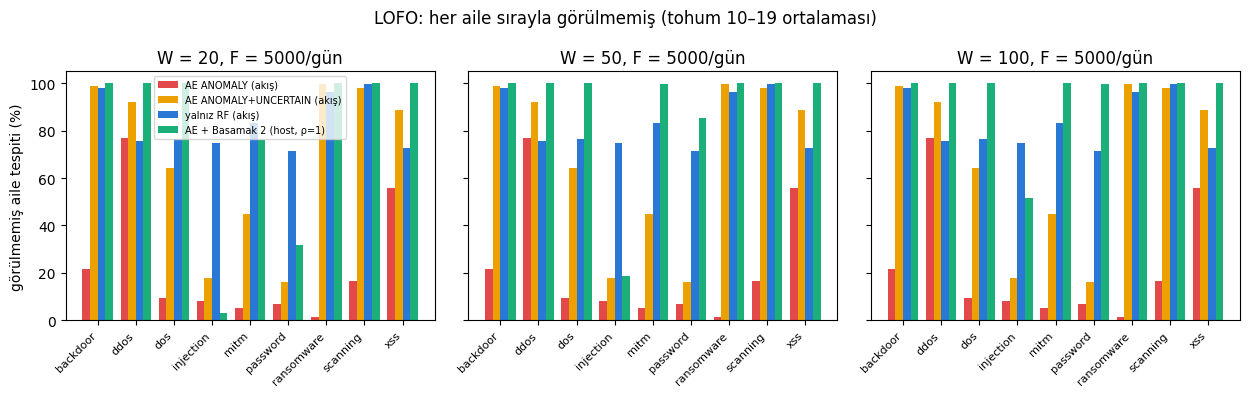

In [7]:
F0 = max(cfg.resolution_flows_per_day)
fig, axs = plt.subplots(1, len(cfg.resolution_windows), figsize=(4.2 * len(cfg.resolution_windows), 4), sharey=True)
for ax, W in zip(np.atleast_1d(axs), cfg.resolution_windows):
    fams = list(fm.index); x = np.arange(len(fams)); w = 0.2
    ae = FLOW.groupby("aile")["AE_ANOMALY"].mean().reindex(fams)
    aeu = (FLOW.groupby("aile")["AE_ANOMALY"].mean() + FLOW.groupby("aile")["AE_UNCERTAIN"].mean()).reindex(fams)
    rf = FLOW.groupby("aile")["RF_tek_recall_α"].mean().reindex(fams)
    h2 = HOST[(HOST["sistem"] == "AE + Basamak 2") & (HOST["W"] == W) & (HOST["F"] == F0)].groupby("aile")[rho1].mean().reindex(fams)
    for j, (vals, lab, col) in enumerate([(ae, "AE ANOMALY (akış)", "#e34948"), (aeu, "AE ANOMALY+UNCERTAIN (akış)", "#eda100"),
                                          (rf, "yalnız RF (akış)", "#2a78d6"), (h2, f"AE + Basamak 2 (host, ρ=1)", "#1baf7a")]):
        ax.bar(x + (j - 1.5) * w, 100 * vals, w, label=lab, color=col)
    ax.set_xticks(x); ax.set_xticklabels(fams, rotation=45, ha="right", fontsize=8); ax.set_title(f"W = {W}, F = {F0}/gün")
np.atleast_1d(axs)[0].set_ylabel("görülmemiş aile tespiti (%)"); np.atleast_1d(axs)[0].legend(fontsize=7)
fig.suptitle("LOFO: her aile sırayla görülmemiş (tohum 10–19 ortalaması)"); fig.tight_layout(); fig.savefig(RUN / "F2_lofo.png", dpi=150)
print("Sonuçlar:", RUN)

In [8]:
# Colab: Drive'a yazılan tüm dosyaların kaydedildiğinden emin ol (oturumu kapatmadan önce mutlaka çalıştırın)
print("Kaydedilen ilerleme:", utils.progress(cfg))
if IN_COLAB:
    drive.flush_and_unmount()
    print("Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.")

Kaydedilen ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '03_kararlar': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '04b_host_eslesmesi': True}
Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.
